## Home Loan Default Prediction Project

In [1]:
# Import libraries 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

# machine learning libraries 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer 
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer 

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
print("All libraries imported successfully!")

All libraries imported successfully!


# Loading the dataset

In [2]:
import os 
data_path="Dataset"
application = pd.read_csv(os.path.join(data_path,"application_train.csv"))
bureau = pd.read_csv(os.path.join(data_path, "bureau.csv"))
bureau_balance = pd.read_csv(os.path.join(data_path, "bureau_balance.csv"))
pos_cash = pd.read_csv(os.path.join(data_path, "pos_cash_balance.csv"))
credit_card = pd.read_csv(os.path.join(data_path, "credit_card_balance.csv"))
previous_application = pd.read_csv(os.path.join(data_path, "previous_application.csv"))
installments = pd.read_csv(os.path.join(data_path, "installments_payments.csv"))
print("All datasets loaded successfully!")

All datasets loaded successfully!


## **Why are you loading all the files?
 **Because the main application file tells us about the current application, While the other files provide historical information.**
 
However, don't process everything at once. First understand the main dataset.

## Understand the main dataset 

In [3]:
#Displaying first five rows 
application.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# number of rows and columns
print("Dataset Shape:", application.shape)
#column names
print("\ncolumn Names:")
print(application.columns.tolist())
# Imformation about columns
application.info()
# Statistical summary
application.describe()

Dataset Shape: (307511, 122)

column Names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


## Data Cleaning 
* Missing Values.
* Duplicates records.
* incorrect data types.
* Unusual Values.
* Outliers.
* Imbalanced target Classes.

## Check missing values

In [5]:
missing_values = application.isnull().sum()
missing_percentage = (application.isnull().sum() / len(application)) * 100
missing_report = pd.DataFrame({
    'Missing_Count': missing_values,
    'Missing_Percentage': missing_percentage
})
missing_report = missing_report.sort_values(
    by='Missing_Percentage',
    ascending=False
)
missing_report.head(30)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


## Check duplicates

In [6]:
print("Duplicate rows:",application.duplicated().sum())
print("Duplicate customer IDs:",application['SK_ID_CURR'].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


## Check data types
This tells you whether each variable is:
- Integer.
- Float.
- Object/string.
- Date or another data type.

Categorical columns must eventually be encoded into numerical representations for most machine learning algorithms.

In [7]:
application.dtypes

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

## Check unusual values
Look for:
- Negative values where they are not meaningful.
- Extremely large values.
- Zero values that may indicate missing or unusual information.
  
Don't automatically delete outliers. Investigate their meaning first

In [8]:
application[
    ['AMT_INCOME_TOTAL',
     'AMT_CREDIT',
     'AMT_ANNUITY',
     'AMT_GOODS_PRICE']
].describe()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05
mean,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05
std,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05
min,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04
25%,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05
50%,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05
75%,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05
max,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06


## Exploratory Data Analysis (EDA)

Understand the target variable
Remember:
- TARGET = 0 → Non-defaulter.
- TARGET = 1 → Defaulter.

First, check the number of customers in each category.

In [9]:
application['TARGET'].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [10]:
# Calculate percentages:
target_percentage = (application['TARGET'].value_counts(normalize=True) * 100)
print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


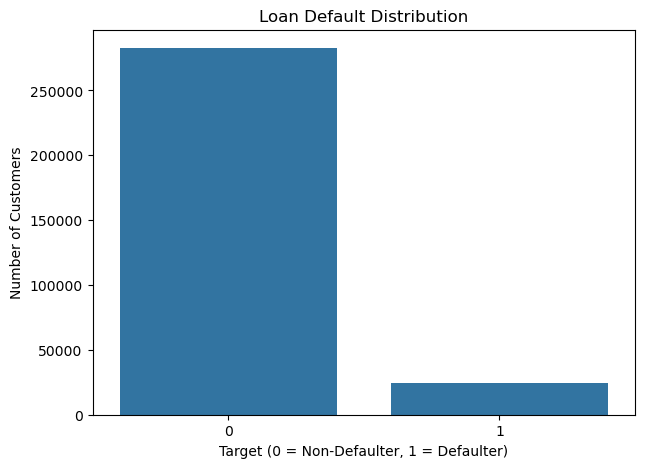

In [11]:
# Countplot
plt.figure(figsize=(7, 5))
sns.countplot(
    data=application,
    x='TARGET'
)
plt.title('Loan Default Distribution')
plt.xlabel('Target (0 = Non-Defaulter, 1 = Defaulter)')
plt.ylabel('Number of Customers')
plt.show()

Univariate analysis

Univariate analysis means studying one variable at a time.

Examples:
- Customer age.
- Income.
- Credit amount.
- Employment duration.
- Education.
- Family size.

## Age distribution

The dataset includes DAYS_BIRTH, which represents age in days as a negative number.

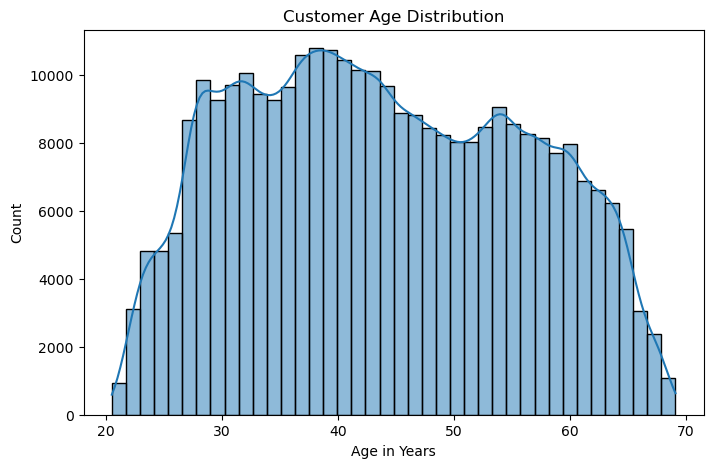

In [12]:
application['AGE_YEARS'] = (
    -application['DAYS_BIRTH'] / 365
)
plt.figure(figsize=(8, 5))
sns.histplot(
    application['AGE_YEARS'],
    bins=40,
    kde=True
)
plt.title('Customer Age Distribution')
plt.xlabel('Age in Years')
plt.show()

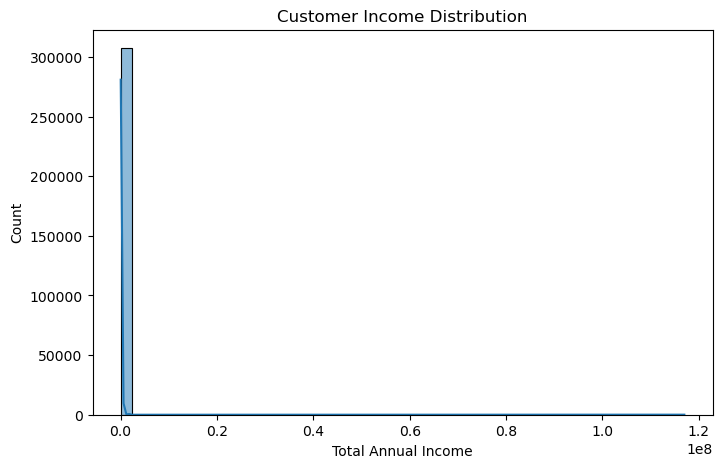

In [13]:
# Income distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    application['AMT_INCOME_TOTAL'],
    bins=50,
    kde=True
)
plt.title('Customer Income Distribution')
plt.xlabel('Total Annual Income')
plt.show()

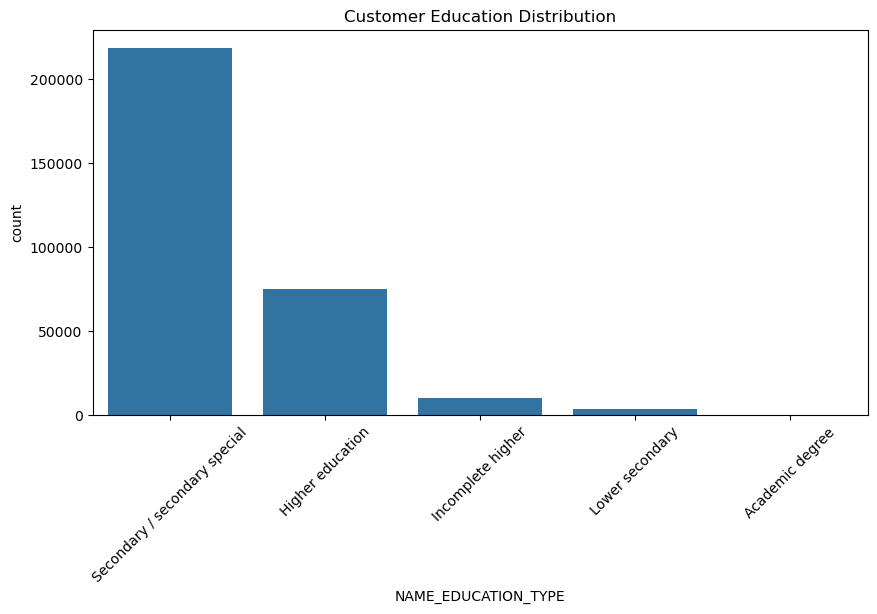

In [14]:
# Education distribution
plt.figure(figsize=(10, 5))
sns.countplot(
    data=application,
    x='NAME_EDUCATION_TYPE'
)
plt.xticks(rotation=45)
plt.title('Customer Education Distribution')
plt.show()

## Bivariate analysis
Bivariate analysis means studying the relationship between two variables.

In this project, we are especially interested in the relationship between customer characteristics and loan default.

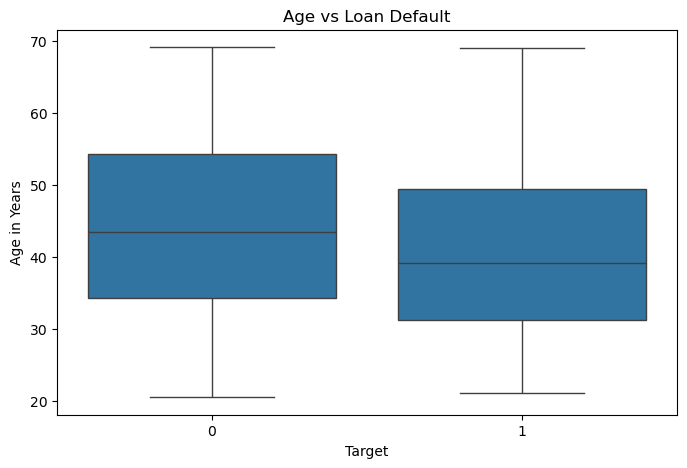

In [15]:
# Does age affect loan default?
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=application,
    x='TARGET',
    y='AGE_YEARS'
)
plt.title('Age vs Loan Default')
plt.xlabel('Target')
plt.ylabel('Age in Years')
plt.show()

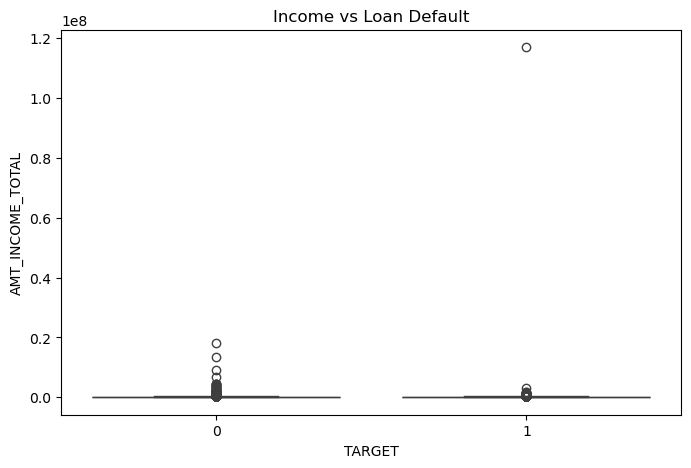

In [16]:
#Does income affect loan default?
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=application,
    x='TARGET',
    y='AMT_INCOME_TOTAL'
)
plt.title('Income vs Loan Default')
plt.show()

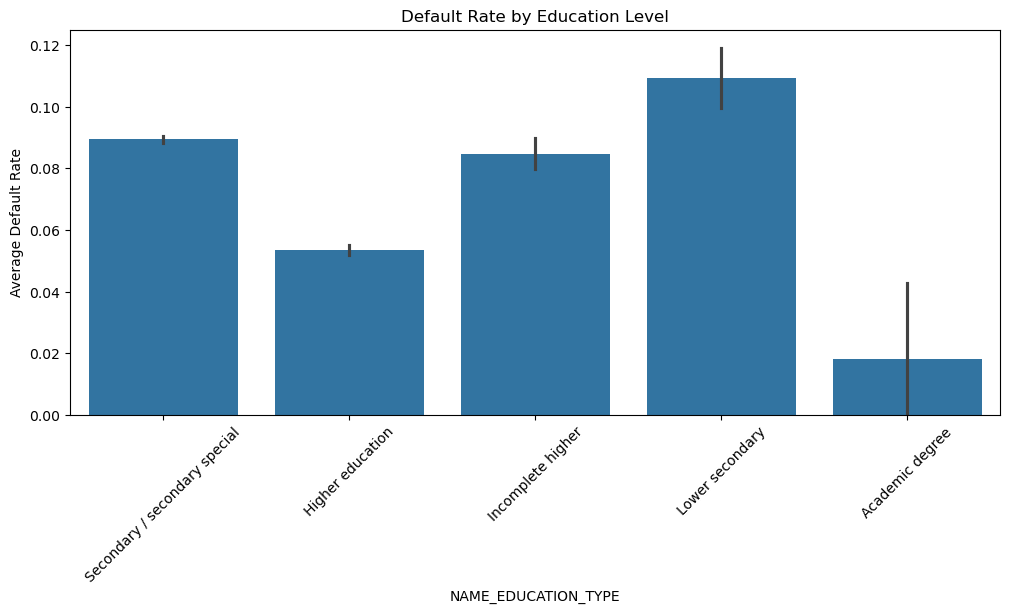

In [17]:
# Does education affect loan default?
plt.figure(figsize=(12, 5))
sns.barplot(
    data=application,
    x='NAME_EDUCATION_TYPE',
    y='TARGET'
)
plt.xticks(rotation=45)
plt.title('Default Rate by Education Level')
plt.ylabel('Average Default Rate')
plt.show()

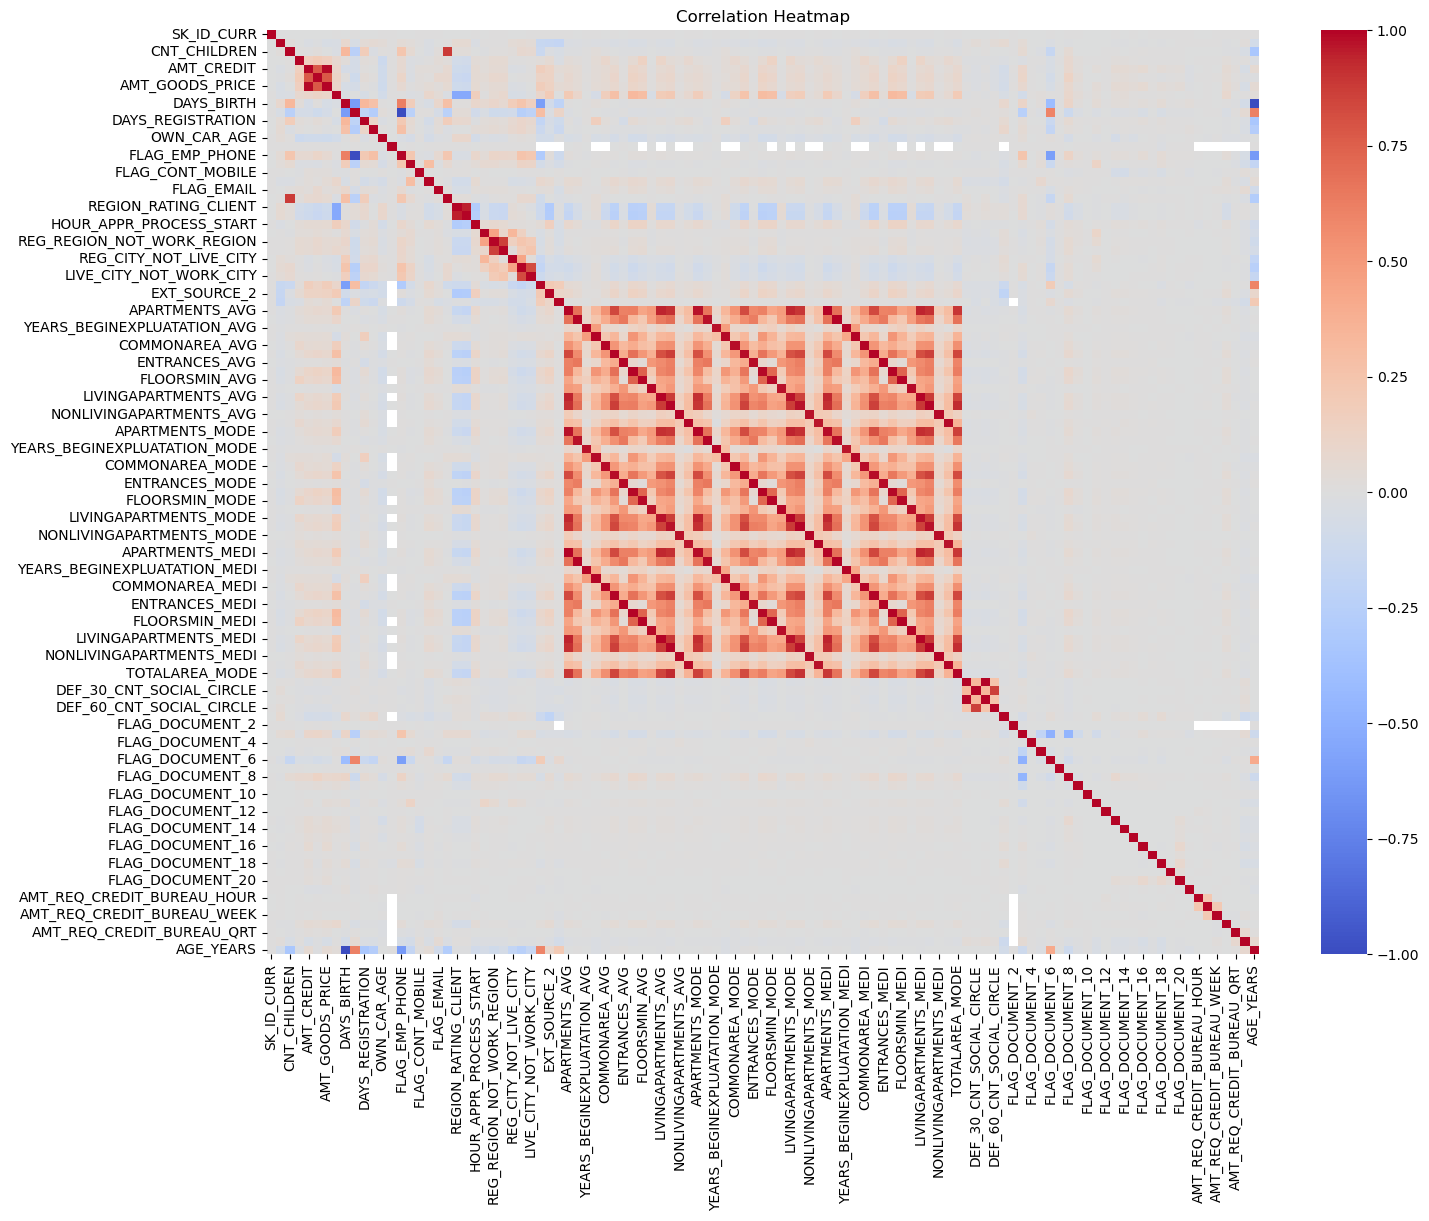

In [18]:
# Correlation analysis
# Correlation tells us how numerical variables are related to each other.
numeric_data = application.select_dtypes(
    include=['int64', 'float64']
)
correlation = numeric_data.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0
)
plt.title('Correlation Heatmap')
plt.show()

Why do we perform correlation analysis?
- Identify relationships between variables.
- Understand possible multicollinearity.
- Find variables associated with the target.
- Support feature selection.

Remember: Correlation does not prove causation, and a weak linear correlation does not necessarily mean a feature is useless.

## Create an EDA conclusion
The exploratory data analysis was conducted to understand customer demographics, income distribution, credit amounts and repayment behaviour. The target variable was examined to understand class imbalance. Relationships between customer characteristics and loan default were investigated using visualizations and statistical summaries. These observations will guide the feature engineering and predictive modelling stages

## Feature Engineering
Create new features

**Age in years**

In [19]:
application['AGE_YEARS'] = (
    -application['DAYS_BIRTH'] / 365)

In [20]:
# Employment experience
application['EMPLOYMENT_YEARS'] = (application['DAYS_EMPLOYED'].clip(upper=0) * -1 / 365)

In [21]:
# Credit-to-income ratio
application['CREDIT_INCOME_RATIO'] = (application['AMT_CREDIT'] /application['AMT_INCOME_TOTAL'].replace(0, np.nan))

In [22]:
# Annuity-to-income ratio
application['ANNUITY_INCOME_RATIO'] = (application['AMT_ANNUITY'] /application['AMT_INCOME_TOTAL'].replace(0, np.nan))

In [24]:
# Goods price to credit ratio
application['GOODS_CREDIT_RATIO'] = (application['AMT_GOODS_PRICE'] /application['AMT_CREDIT'].replace(0, np.nan))

# Process the other six datasets
#Aggregate bureau.csv
For example, one customer may have multiple previous loans.

We can calculate:
- Number of previous bureau loans.
- Average previous credit amount.
- Total credit amount.
- Average outstanding debt.

In [26]:
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_CREDIT_MEAN=('AMT_CREDIT_SUM', 'mean'),
    BUREAU_CREDIT_TOTAL=('AMT_CREDIT_SUM', 'sum'),
    BUREAU_DEBT_MEAN=('AMT_CREDIT_SUM_DEBT', 'mean')
).reset_index()

In [27]:
# Aggregate bureau_balance.csv
bureau_balance_agg = bureau_balance.groupby(
    'SK_ID_BUREAU'
).agg(
    BUREAU_MONTHS=('MONTHS_BALANCE', 'count'),
    BUREAU_STATUS_COUNT=('STATUS', 'nunique')
).reset_index()

In [29]:
# Then connect the summary to customer identifiers using the bureau table:
bureau_customer = bureau[
    ['SK_ID_CURR', 'SK_ID_BUREAU']
].merge(
    bureau_balance_agg,
    on='SK_ID_BUREAU',
    how='left'
)
bureau_balance_customer = bureau_customer.groupby(
    'SK_ID_CURR'
).agg(
    BB_MONTHS_MEAN=('BUREAU_MONTHS', 'mean'),
    BB_STATUS_VARIETY=('BUREAU_STATUS_COUNT', 'mean')
).reset_index()

In [30]:
# Aggregate POS_CASH_balance.csv
pos_agg = pos_cash.groupby('SK_ID_CURR').agg(
    POS_MONTHS=('MONTHS_BALANCE', 'count'),
    POS_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),
    POS_REMAINING_MEAN=('CNT_INSTALMENT_FUTURE', 'mean')
).reset_index()

In [31]:
# Aggregate credit_card_balance.csv
credit_card_agg = credit_card.groupby(
    'SK_ID_CURR'
).agg(
    CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
    CC_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),
    CC_DRAWINGS_MEAN=('AMT_DRAWINGS_CURRENT', 'mean')
).reset_index()

In [32]:
# Aggregate previous_application.csv
previous_agg = previous_application.groupby(
    'SK_ID_CURR'
).agg(
    PREVIOUS_APP_COUNT=('SK_ID_PREV', 'count'),
    PREVIOUS_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
    PREVIOUS_APPLICATION_MEAN=('AMT_APPLICATION', 'mean')
).reset_index()

In [33]:
# Aggregate installments_payments.csv
installments['PAYMENT_DIFFERENCE'] = (
    installments['AMT_INSTALMENT'] -
    installments['AMT_PAYMENT']
)

installments['PAYMENT_DELAY'] = (
    installments['DAYS_ENTRY_PAYMENT'] -
    installments['DAYS_INSTALMENT']
)

installments_agg = installments.groupby(
    'SK_ID_CURR'
).agg(
    PAYMENT_DELAY_MEAN=('PAYMENT_DELAY', 'mean'),
    PAYMENT_DIFFERENCE_MEAN=('PAYMENT_DIFFERENCE', 'mean'),
    PAYMENT_RECORD_COUNT=('SK_ID_PREV', 'count')
).reset_index()

In [34]:
# Merge all aggregated datasets
final_data = application.copy()

aggregated_datasets = [
    bureau_agg,
    bureau_balance_customer,
    pos_agg,
    credit_card_agg,
    previous_agg,
    installments_agg
]

for data in aggregated_datasets:

    final_data = final_data.merge(
        data,
        on='SK_ID_CURR',
        how='left'
    )

print("Final Dataset Shape:", final_data.shape)

Final Dataset Shape: (307511, 145)


In [35]:
# Prepare the data for machine learning
X = final_data.drop(
    columns=['TARGET', 'SK_ID_CURR']
)
y = final_data['TARGET']

In [36]:
# Handle categorical and numerical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numeric Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

Numeric Features: 127
Categorical Features: 16


In [38]:
# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (246008, 143)
Testing Data: (61503, 143)


In [39]:
# Handle missing values and encode categories
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Build machine learning models
# Train Logistic Regression

In [40]:
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained!")

Logistic Regression trained!


In [41]:
# Train Random Forest
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=10,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained!")

Random Forest trained!


In [43]:
# Train XGBoost
!pip install xgboost

In [44]:
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric='auc',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost trained!")

XGBoost trained!


## Evaluate your machine learning models

In [45]:
# Create an evaluation function
def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, predictions, zero_division=0
        ),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(
            y_test, probabilities
        )
    }

    return results

In [46]:
# Compare all models
models = [
    (logistic_model, 'Logistic Regression'),
    (random_forest_model, 'Random Forest'),
    (xgb_model, 'XGBoost')
]

results = []

for model, name in models:

    result = evaluate_model(
        model,
        X_test,
        y_test,
        name
    )

    results.append(result)

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.699820,0.168101,0.688419,0.270219,0.758994,0.240890
1,Random Forest,0.829016,0.215187,0.422356,0.285112,0.741388,0.221308
2,XGBoost,0.920199,0.612648,0.031219,0.059410,0.777604,0.275788


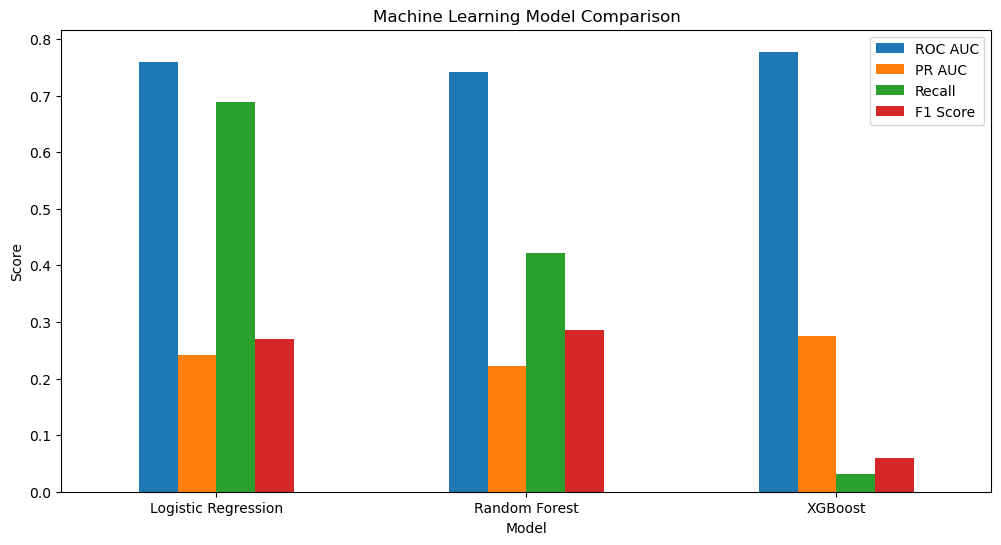

In [47]:
# Create a comparison graph:
comparison_df.set_index('Model')[
    ['ROC AUC', 'PR AUC', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.show()

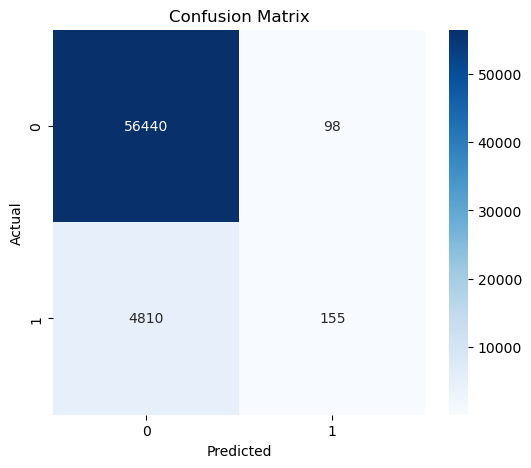

In [48]:
# Confusion matrix
best_model = xgb_model

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [49]:
# Feature importance
# For tree-based models, you can extract feature importance
feature_names = (
    best_model.named_steps['preprocessor']
    .get_feature_names_out()
)

importance = (
    best_model.named_steps['classifier']
    .feature_importances_
)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
29,num__EXT_SOURCE_3,0.044897
28,num__EXT_SOURCE_2,0.044205
152,cat__NAME_EDUCATION_TYPE_Higher education,0.023757
129,cat__CODE_GENDER_F,0.017347
150,cat__NAME_INCOME_TYPE_Working,0.017062
130,cat__CODE_GENDER_M,0.015390
108,num__GOODS_CREDIT_RATIO,0.012474
27,num__EXT_SOURCE_1,0.012350
79,num__FLAG_DOCUMENT_3,0.011650
104,num__AGE_YEARS,0.010720


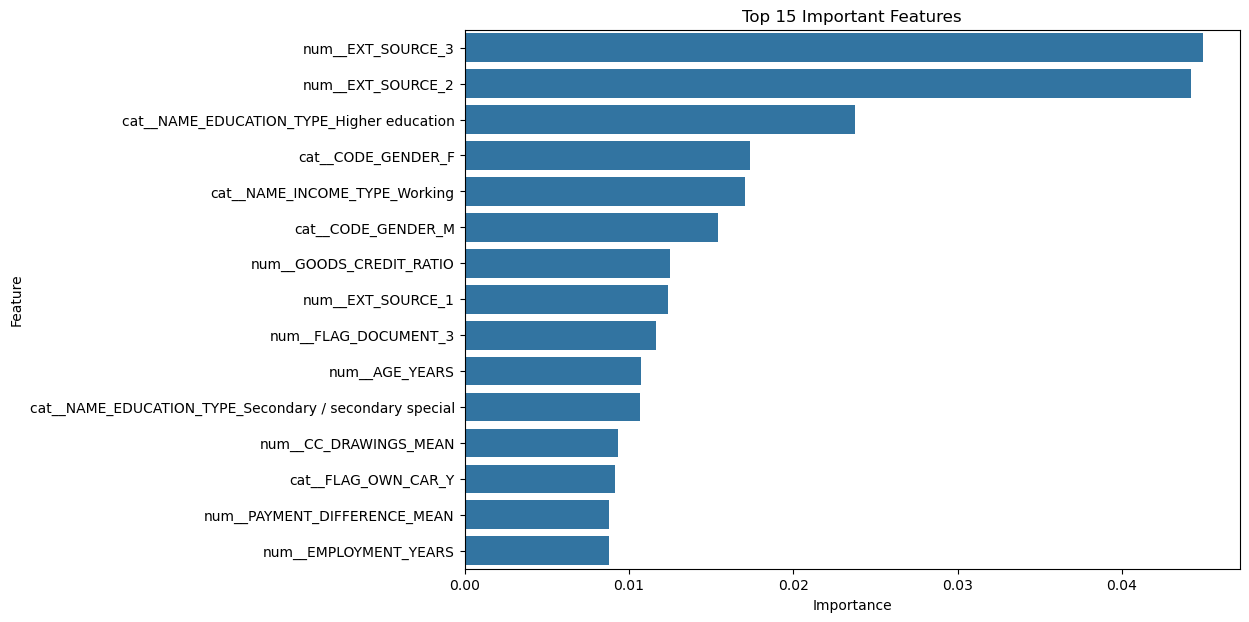

In [50]:
# Visualize it:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features')

plt.show()

In [51]:
# Identify customer segments
application['INCOME_GROUP'] = pd.cut(
    application['AMT_INCOME_TOTAL'],
    bins=4,
    labels=[
        'Low Income',
        'Medium Income',
        'High Income',
        'Very High Income'
    ]
)

segment_analysis = application.groupby(
    'INCOME_GROUP',
    observed=False
).agg(
    CUSTOMER_COUNT=('TARGET', 'count'),
    DEFAULT_RATE=('TARGET', 'mean')
).reset_index()

segment_analysis

,INCOME_GROUP,CUSTOMER_COUNT,DEFAULT_RATE
0,Low Income,307510,0.080726
1,Medium Income,0,NaN
2,High Income,0,NaN
3,Very High Income,1,1.000000


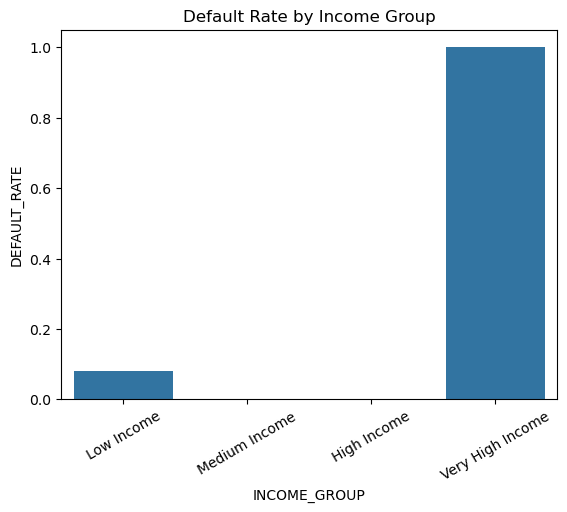

In [52]:
# You can visualize the default rate:
sns.barplot(
    data=segment_analysis,
    x='INCOME_GROUP',
    y='DEFAULT_RATE'
)

plt.title('Default Rate by Income Group')
plt.xticks(rotation=30)
plt.show()

Important distinction: Your model predicts default risk. It does not automatically establish legal or financial loan eligibility. A bank must define its approval policy, risk appetite, affordability criteria and regulatory requirements separately.